In [1]:
# ==========================================
# Cell 1: Import Libraries
# ==========================================

import os
import zipfile
from pathlib import Path
from typing import Tuple, Optional, Union

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ==========================================
# Cell 2: Dataset Path Configuration
# ==========================================

CANDIDATE_DATASET_PATHS = [
    Path("../data/dataset.zip"),
    Path("../data/kvasir-seg.zip"),
    Path("data/dataset.zip"),
    Path("data/kvasir-seg.zip"),
    Path(r"c:\Users\ohmar\OneDrive\Desktop\kvasir-seg.zip"),
    Path.home() / "Desktop" / "kvasir-seg.zip"
]

def get_kvasir_dataset_path() -> Optional[Path]:
    for candidate in CANDIDATE_DATASET_PATHS:
        if candidate.is_file():
            return candidate
    return None

dataset_zip_path = get_kvasir_dataset_path()
if dataset_zip_path:
    print(f"Found Kvasir-SEG archive at: {dataset_zip_path.resolve()}")
else:
    print("Warning: Kvasir-SEG zip not found in default locations.")

Found Kvasir-SEG archive at: C:\Users\ohmar\OneDrive\Desktop\image processing\image_project\data\dataset.zip


In [3]:
# ==========================================
# Cell 3: Mean Squared Error (MSE)
# ==========================================

def calculate_mse(
    y_true: np.ndarray,
    y_pred: np.ndarray
) -> float:
    """
    Calculate the Mean Squared Error (MSE) between two images or arrays.

    Formula:
        MSE = (1 / N) * sum((y_true - y_pred) ** 2)

    Parameters:
        y_true (np.ndarray): Ground truth image / array.
        y_pred (np.ndarray): Predicted / reconstructed image or array.

    Returns:
        float: Mean Squared Error value.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if y_true.shape != y_pred.shape:
        raise ValueError(
            f"Shape mismatch: y_true {y_true.shape} vs y_pred {y_pred.shape}"
        )

    # Cast to float64 to avoid unsigned integer overflow / underflow
    diff = y_true.astype(np.float64) - y_pred.astype(np.float64)
    mse_value = float(np.mean(diff ** 2))

    return mse_value

print("calculate_mse defined.")

calculate_mse defined.


In [4]:
# ==========================================
# Cell 4: Peak Signal-to-Noise Ratio (PSNR)
# ==========================================

def calculate_psnr(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    max_val: float = 255.0
) -> float:
    """
    Calculate the Peak Signal-to-Noise Ratio (PSNR) in decibels (dB).

    Formula:
        PSNR = 10 * log10(max_val^2 / MSE)
             = 20 * log10(max_val / sqrt(MSE))

    Parameters:
        y_true (np.ndarray): Ground truth image / array.
        y_pred (np.ndarray): Predicted / reconstructed image.
        max_val (float): Maximum possible pixel value (default 255.0 for 8-bit images,
                         or 1.0 for normalized float images).

    Returns:
        float: PSNR value in dB (float('inf') if MSE is 0).
    """
    mse_value = calculate_mse(y_true, y_pred)

    if mse_value == 0.0:
        return float("inf")

    psnr_value = float(10.0 * np.log10((max_val ** 2) / mse_value))

    return psnr_value

print("calculate_psnr defined.")

calculate_psnr defined.


In [5]:
# ==========================================
# Cell 5: Intersection over Union (IoU)
# ==========================================

def calculate_iou(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    threshold: float = 0.5
) -> float:
    """
    Calculate the Intersection over Union (IoU / Jaccard Index) for segmentation masks.

    Formula:
        IoU = |A ∩ B| / |A ∪ B|

    Parameters:
        y_true (np.ndarray): Ground truth mask (binary or probability).
        y_pred (np.ndarray): Predicted mask (binary or probability).
        threshold (float): Threshold to binarize non-boolean masks (default: 0.5).

    Returns:
        float: IoU score between 0.0 and 1.0. If both masks are empty, returns 1.0.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if y_true.shape != y_pred.shape:
        raise ValueError(
            f"Shape mismatch: y_true {y_true.shape} vs y_pred {y_pred.shape}"
        )

    # Convert to boolean binary masks
    mask_true = y_true if y_true.dtype == bool else (y_true > threshold)
    mask_pred = y_pred if y_pred.dtype == bool else (y_pred > threshold)

    intersection = int(np.logical_and(mask_true, mask_pred).sum())
    union = int(np.logical_or(mask_true, mask_pred).sum())

    # Edge case: both masks are empty
    if union == 0:
        return 1.0

    iou_value = float(intersection / union)

    return iou_value

print("calculate_iou defined.")

calculate_iou defined.


In [6]:
# ==========================================
# Cell 6: Load Sample from Kvasir-SEG Dataset
# ==========================================

def load_kvasir_sample(
    zip_path: Optional[Union[str, Path]] = None,
    sample_index: int = 0
) -> Tuple[np.ndarray, np.ndarray, str]:
    """
    Load an image and its corresponding ground-truth segmentation mask
    from the dataset ZIP file in the original dataset order (matches data.py).

    Returns:
        Tuple[image_rgb, mask_binary, sample_name]
    """
    if zip_path is None:
        zip_path = get_kvasir_dataset_path()

    if zip_path is None or not Path(zip_path).is_file():
        raise FileNotFoundError(
            f"Dataset not found. Checked: {[str(p) for p in CANDIDATE_DATASET_PATHS]}"
        )

    zip_path = Path(zip_path)

    with zipfile.ZipFile(zip_path, "r") as archive:
        all_files = archive.namelist()
        image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

        image_files = []
        mask_map = {}

        for file in all_files:
            if file.lower().endswith(image_extensions):
                if "/masks/" in file.lower() or file.lower().startswith("masks/"):
                    name = Path(file).stem
                    mask_map[name] = file
                elif "/images/" in file.lower() or file.lower().startswith("images/"):
                    image_files.append(file)

        if not image_files:
            raise ValueError(f"No images found inside {zip_path}")

        sample_img_file = image_files[sample_index % len(image_files)]
        sample_name = Path(sample_img_file).stem

        if sample_name not in mask_map:
            raise ValueError(f"Matching mask for '{sample_name}' not found in archive")

        sample_mask_file = mask_map[sample_name]

        # Read and decode image (RGB)
        img_bytes = archive.read(sample_img_file)
        img_arr = np.frombuffer(img_bytes, dtype=np.uint8)
        image = cv2.imdecode(img_arr, cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Read and decode mask (Binary uint8: 0 or 1)
        mask_bytes = archive.read(sample_mask_file)
        mask_arr = np.frombuffer(mask_bytes, dtype=np.uint8)
        mask = cv2.imdecode(mask_arr, cv2.IMREAD_GRAYSCALE)
        mask_binary = (mask > 127).astype(np.uint8)

        return image, mask_binary, sample_name


image, mask, sample_name = load_kvasir_sample(sample_index=0)
print(f"Loaded Sample: {sample_name}.jpg")
print(f"Image Shape  : {image.shape}")
print(f"Mask Shape   : {mask.shape} (Polyp pixel count: {mask.sum()})")

Loaded Sample: ck2bxiswtxuw80838qkisqjwz.jpg
Image Shape  : (520, 621, 3)
Mask Shape   : (520, 621) (Polyp pixel count: 142856)


In [7]:
# ==========================================
# Cell 7: Hand-Crafted Verification Tests (from src/metrics.py)
# ==========================================

def run_hand_crafted_tests() -> None:
    """
    Test MSE, PSNR, and IoU on small hand-worked arrays
    to verify mathematical correctness.
    """
    print("=" * 60)
    print("Running Hand-Crafted Verification Tests on Small Arrays")
    print("=" * 60)

    # ----------------------------------------------------
    # Test 1: MSE Test on 2x2 Array
    # Hand Calculation:
    # Array True:  [[10, 20], [30, 40]]
    # Array Pred:  [[12, 20], [25, 40]]
    # Errors:      [-2,   0,   5,   0]
    # Squared:     [ 4,   0,  25,   0]
    # Sum of Sq:   29
    # Total items: 4
    # Expected MSE = 29 / 4 = 7.25
    # ----------------------------------------------------
    a_true = np.array([[10, 20], [30, 40]], dtype=np.uint8)
    a_pred = np.array([[12, 20], [25, 40]], dtype=np.uint8)

    computed_mse = calculate_mse(a_true, a_pred)
    expected_mse = 7.25

    print(f"\n[Test 1] MSE Check:")
    print(f"  y_true:\n{a_true}")
    print(f"  y_pred:\n{a_pred}")
    print(f"  Expected MSE : {expected_mse}")
    print(f"  Computed MSE : {computed_mse}")
    assert np.isclose(computed_mse, expected_mse), f"MSE failed: {computed_mse} != {expected_mse}"
    print("  -> Result: PASSED (Hand calculation matches)")

    # ----------------------------------------------------
    # Test 2: PSNR Test with max_val = 255.0
    # Hand Calculation:
    # max_val = 255
    # MSE = 7.25
    # PSNR = 10 * log10(255^2 / 7.25) = 10 * log10(65025 / 7.25)
    #      = 10 * log10(8968.96551724) ≈ 39.52742 dB
    # ----------------------------------------------------
    computed_psnr = calculate_psnr(a_true, a_pred, max_val=255.0)
    expected_psnr = 10.0 * np.log10((255.0 ** 2) / 7.25)

    print(f"\n[Test 2] PSNR Check:")
    print(f"  Expected PSNR: {expected_psnr:.5f} dB")
    print(f"  Computed PSNR: {computed_psnr:.5f} dB")
    assert np.isclose(computed_psnr, expected_psnr), f"PSNR failed: {computed_psnr} != {expected_psnr}"
    print("  -> Result: PASSED (Hand calculation matches)")

    # Test 2b: PSNR Identical Images (Zero MSE -> inf)
    identical_psnr = calculate_psnr(a_true, a_true, max_val=255.0)
    print(f"\n[Test 2b] PSNR Identical Images (Zero MSE):")
    print(f"  Expected PSNR: inf")
    print(f"  Computed PSNR: {identical_psnr}")
    assert identical_psnr == float("inf"), "Identical PSNR should be infinity"
    print("  -> Result: PASSED")

    # ----------------------------------------------------
    # Test 3: IoU Test on 3x3 Binary Mask
    # Hand Calculation:
    # Mask True:
    #   [[1, 1, 0],
    #    [0, 1, 0],
    #    [0, 0, 0]]  -> 3 positive pixels
    #
    # Mask Pred:
    #   [[1, 0, 0],
    #    [0, 1, 1],
    #    [0, 0, 0]]  -> 3 positive pixels
    #
    # Intersection: pixels where both are 1 -> (0,0) and (1,1) -> count = 2
    # Union: pixels where either is 1 -> (0,0), (0,1), (1,1), (1,2) -> count = 4
    # Expected IoU = 2 / 4 = 0.50 (50.0%)
    # ----------------------------------------------------
    m_true = np.array([
        [1, 1, 0],
        [0, 1, 0],
        [0, 0, 0]
    ], dtype=np.uint8)

    m_pred = np.array([
        [1, 0, 0],
        [0, 1, 1],
        [0, 0, 0]
    ], dtype=np.uint8)

    computed_iou = calculate_iou(m_true, m_pred, threshold=0.5)
    expected_iou = 0.50

    print(f"\n[Test 3] IoU Check:")
    print(f"  Mask True:\n{m_true}")
    print(f"  Mask Pred:\n{m_pred}")
    print(f"  Intersection count : 2")
    print(f"  Union count        : 4")
    print(f"  Expected IoU       : {expected_iou}")
    print(f"  Computed IoU       : {computed_iou}")
    assert np.isclose(computed_iou, expected_iou), f"IoU failed: {computed_iou} != {expected_iou}"
    print("  -> Result: PASSED (Hand calculation matches)")

    # ----------------------------------------------------
    # Test 4: IoU Edge Cases
    # Empty masks -> IoU = 1.0
    # Disjoint masks -> IoU = 0.0
    # ----------------------------------------------------
    empty_true = np.zeros((3, 3), dtype=np.uint8)
    empty_pred = np.zeros((3, 3), dtype=np.uint8)
    empty_iou = calculate_iou(empty_true, empty_pred)
    assert empty_iou == 1.0, f"Empty masks IoU failed: {empty_iou} != 1.0"

    disjoint_true = np.array([[1, 0], [0, 0]])
    disjoint_pred = np.array([[0, 1], [0, 0]])
    disjoint_iou = calculate_iou(disjoint_true, disjoint_pred)
    assert disjoint_iou == 0.0, f"Disjoint masks IoU failed: {disjoint_iou} != 0.0"

    print(f"\n[Test 4] IoU Edge Cases (Empty & Disjoint):")
    print(f"  Empty masks IoU   : {empty_iou} (Expected: 1.0)")
    print(f"  Disjoint masks IoU: {disjoint_iou} (Expected: 0.0)")
    print("  -> Result: PASSED")

    print("\n" + "=" * 60)
    print("All Hand-Crafted Verification Tests Passed Successfully!")
    print("=" * 60)


run_hand_crafted_tests()

Running Hand-Crafted Verification Tests on Small Arrays

[Test 1] MSE Check:
  y_true:
[[10 20]
 [30 40]]
  y_pred:
[[12 20]
 [25 40]]
  Expected MSE : 7.25
  Computed MSE : 7.25
  -> Result: PASSED (Hand calculation matches)

[Test 2] PSNR Check:
  Expected PSNR: 39.52742 dB
  Computed PSNR: 39.52742 dB
  -> Result: PASSED (Hand calculation matches)

[Test 2b] PSNR Identical Images (Zero MSE):
  Expected PSNR: inf
  Computed PSNR: inf
  -> Result: PASSED

[Test 3] IoU Check:
  Mask True:
[[1 1 0]
 [0 1 0]
 [0 0 0]]
  Mask Pred:
[[1 0 0]
 [0 1 1]
 [0 0 0]]
  Intersection count : 2
  Union count        : 4
  Expected IoU       : 0.5
  Computed IoU       : 0.5
  -> Result: PASSED (Hand calculation matches)

[Test 4] IoU Edge Cases (Empty & Disjoint):
  Empty masks IoU   : 1.0 (Expected: 1.0)
  Disjoint masks IoU: 0.0 (Expected: 0.0)
  -> Result: PASSED

All Hand-Crafted Verification Tests Passed Successfully!


In [8]:
# ==========================================
# Cell 8: Kvasir-SEG Dataset Evaluation (from src/metrics.py)
# ==========================================

def run_kvasir_dataset_evaluation(
    zip_path: Optional[Union[str, Path]] = None,
    sample_index: int = 0
) -> None:
    """
    Demonstrate MSE, PSNR, and IoU on real dataset samples
    from Kvasir-SEG (ck2bxiswtxuw80838qkisqjwz).
    """
    print("\n" + "=" * 60)
    print("Running Metrics Validation on Dataset (ck2bxiswtxuw80838qkisqjwz)")
    print("=" * 60)

    try:
        image, gt_mask, sample_name = load_kvasir_sample(zip_path, sample_index)
        print(f"Image: {sample_name}.jpg")
        print(f"Original Image Shape: {image.shape}")
        print(f"Original Mask Shape : {gt_mask.shape} (Polyp pixel count: {gt_mask.sum()})")

        # Simulate noisy image and restoration for MSE & PSNR evaluation
        np.random.seed(42)
        noise = np.random.normal(0, 20, image.shape)
        noisy_image = np.clip(image.astype(np.float64) + noise, 0, 255).astype(np.uint8)
        restored_image = cv2.GaussianBlur(noisy_image, (5, 5), 0)

        noisy_mse = calculate_mse(image, noisy_image)
        noisy_psnr = calculate_psnr(image, noisy_image)
        restored_mse = calculate_mse(image, restored_image)
        restored_psnr = calculate_psnr(image, restored_image)

        print("\n[Image Quality Evaluation - MSE & PSNR]")
        print(f"  Original vs Noisy Image     -> MSE: {noisy_mse:8.2f} | PSNR: {noisy_psnr:5.2f} dB")
        print(f"  Original vs Restored Image  -> MSE: {restored_mse:8.2f} | PSNR: {restored_psnr:5.2f} dB")

        # Evaluate segmentation mask IoU
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
        pred_dilated = cv2.dilate(gt_mask, kernel, iterations=1)
        pred_eroded = cv2.erode(gt_mask, kernel, iterations=1)

        iou_dilated = calculate_iou(gt_mask, pred_dilated)
        iou_eroded = calculate_iou(gt_mask, pred_eroded)

        print("\n[Segmentation Mask Overlap Evaluation - IoU]")
        print(f"  Ground Truth Area : {gt_mask.sum()} pixels")
        print(f"  Dilated Mask IoU  : {iou_dilated:.4f} ({iou_dilated * 100:.2f}%)")
        print(f"  Eroded Mask IoU   : {iou_eroded:.4f} ({iou_eroded * 100:.2f}%)")

        print("\n" + "=" * 60)
        print("Dataset Metrics Evaluation Completed Successfully!")
        print("=" * 60)

    except FileNotFoundError as e:
        print(f"\n[Notice] {e}")


run_kvasir_dataset_evaluation()


Running Metrics Validation on Dataset (ck2bxiswtxuw80838qkisqjwz)
Image: ck2bxiswtxuw80838qkisqjwz.jpg
Original Image Shape: (520, 621, 3)
Original Mask Shape : (520, 621) (Polyp pixel count: 142856)

[Image Quality Evaluation - MSE & PSNR]
  Original vs Noisy Image     -> MSE:   339.82 | PSNR: 22.82 dB
  Original vs Restored Image  -> MSE:    49.04 | PSNR: 31.22 dB

[Segmentation Mask Overlap Evaluation - IoU]
  Ground Truth Area : 142856 pixels
  Dilated Mask IoU  : 0.9099 (90.99%)
  Eroded Mask IoU   : 0.8911 (89.11%)

Dataset Metrics Evaluation Completed Successfully!


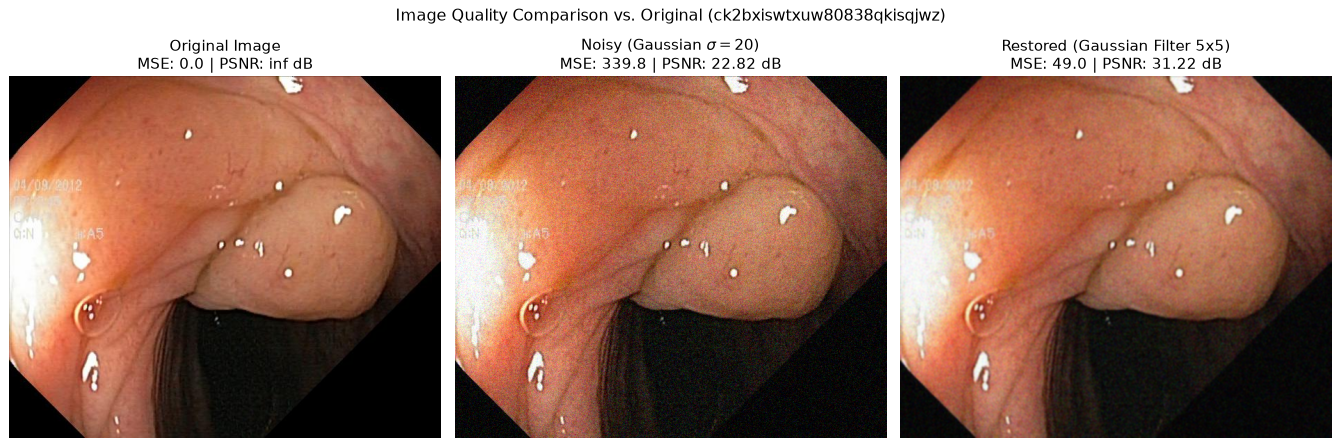

In [9]:
# ==========================================
# Cell 9: Visual Comparison of Image Quality with MSE & PSNR
# ==========================================

np.random.seed(42)
noise = np.random.normal(0, 20, image.shape)
noisy_image = np.clip(image.astype(np.float64) + noise, 0, 255).astype(np.uint8)
restored_image = cv2.GaussianBlur(noisy_image, (5, 5), 0)

images = [image, noisy_image, restored_image]
titles = ["Original Image", "Noisy (Gaussian $\sigma=20$)", "Restored (Gaussian Filter 5x5)"]

plt.figure(figsize=(15, 5), dpi=90)
for i in range(len(images)):
    mse_v = calculate_mse(image, images[i])
    psnr_v = calculate_psnr(image, images[i])
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(f"{titles[i]}\nMSE: {mse_v:.1f} | PSNR: {psnr_v:.2f} dB")
    plt.axis("off")

plt.suptitle("Image Quality Comparison vs. Original (ck2bxiswtxuw80838qkisqjwz)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

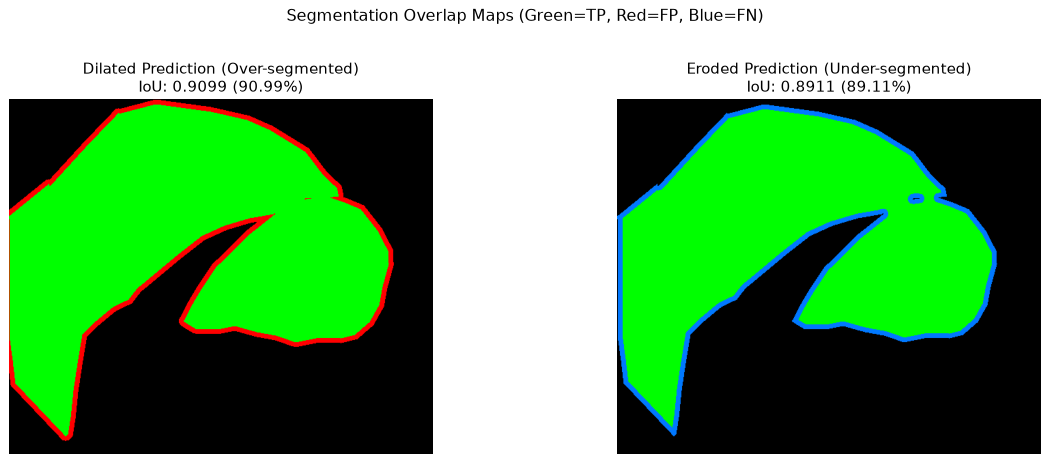

In [10]:
# ==========================================
# Cell 10: Visual Comparison of Segmentation IoU Overlap
# ==========================================

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
pred_dilated = cv2.dilate(mask, kernel, iterations=1)
pred_eroded = cv2.erode(mask, kernel, iterations=1)

preds = [
    ("Dilated Prediction (Over-segmented)", pred_dilated),
    ("Eroded Prediction (Under-segmented)", pred_eroded)
]

plt.figure(figsize=(14, 5), dpi=90)
for i, (name, pmask) in enumerate(preds):
    iou_v = calculate_iou(mask, pmask)
    
    # Construct color overlap map: Green = TP (Overlap), Red = FP, Blue = FN
    overlap = np.zeros((*mask.shape, 3), dtype=np.uint8)
    overlap[(mask == 1) & (pmask == 1)] = [0, 255, 0]   # TP (Intersection)
    overlap[(mask == 0) & (pmask == 1)] = [255, 0, 0]   # FP
    overlap[(mask == 1) & (pmask == 0)] = [0, 120, 255] # FN
    
    plt.subplot(1, 2, i + 1)
    plt.imshow(overlap)
    plt.title(f"{name}\nIoU: {iou_v:.4f} ({iou_v * 100:.2f}%)")
    plt.axis("off")

plt.suptitle("Segmentation Overlap Maps (Green=TP, Red=FP, Blue=FN)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### 🚀 Integration with Project Pipeline

This module directly provides:
* `calculate_mse(image_a, image_b)`
* `calculate_psnr(image_a, image_b)`
* `calculate_iou(mask_a, mask_b)`

These functions are exported and used across all project modules (`src/metrics.py`, `src/enhancement.py`, and notebooks).